# TP 2 — Apprentissage profond avec TensorFlow / Keras
## Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)
Module : Technologies IA — ENSA Fès — Pr. Youness IDRISSI KHAMLICHI

## 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

tf.keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)
print("Keras version:", tf.keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1


### Réponses
1. **TensorFlow vs Keras** : TensorFlow est le moteur de calcul (tenseurs, différentiation automatique, exécution CPU/GPU/TPU, déploiement). Keras est l'API haut niveau intégrée (`tf.keras`) qui permet de définir, compiler et entraîner un modèle en quelques lignes, sans écrire le calcul des gradients.
2. **Flatten** : transforme chaque image 2D 28×28 en vecteur 1D de 784 valeurs, sans aucun paramètre, pour pouvoir la connecter aux couches `Dense` qui attendent un vecteur.
3. **Version installée** : TensorFlow **2.21.0** (Keras 3.15.1) sur la machine d'exécution ; la valeur exacte s'affiche dans la sortie de la cellule ci-dessus.
4. **Sequential / Dense** : `Sequential` empile les couches de façon linéaire (une entrée, une sortie). `Dense` est une couche entièrement connectée : chaque neurone calcule `activation(W·x + b)` à partir de toutes les sorties de la couche précédente.

## 2. Chargement et préparation du dataset

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Type avant normalisation:", x_train.dtype, "| min:", x_train.min(), "| max:", x_train.max())

x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("Type après normalisation:", x_train.dtype, "| min:", x_train.min(), "| max:", x_train.max())
print("Répartition des classes (train):", np.bincount(y_train))

Type avant normalisation: uint8 | min: 0 | max: 255
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
Type après normalisation: float64 | min: 0.0 | max: 1.0
Répartition des classes (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


### Réponses
1. **Pourquoi normaliser ?** Les pixels passent de [0, 255] à [0, 1]. Les entrées sont ainsi à la même échelle que les poids initiaux : les gradients restent stables, les fonctions d'activation ne saturent pas et la convergence est plus rapide.
2. **Taille et type d'une image** : 28 × 28 pixels, un seul canal (niveaux de gris). Type `uint8` (0–255) à l'origine, `float64` (0–1) après la division par 255.0.
3. **Nombre d'exemples d'entraînement** : 60 000 images (et 10 000 pour le test).

## 3. Visualisation d'échantillons

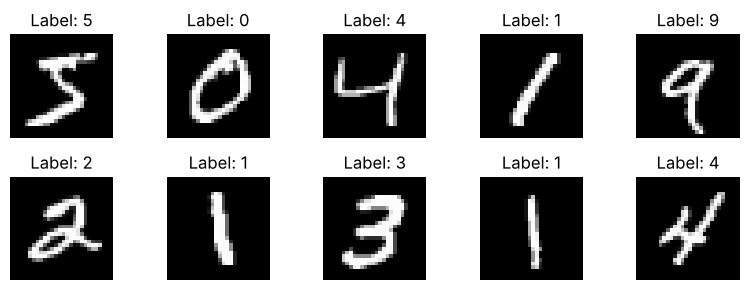

In [3]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

**À faire** : les chiffres affichés sont 5, 0, 4, 1, 9, 2, 1, 3, 1, 4 ; chaque image correspond bien à son label.

### Réponses
1. **Modifier le nombre d'images** : c'est `range(10)` qui fixe le nombre d'images ; il faut adapter en même temps la grille `plt.subplot(lignes, colonnes, i + 1)` (par ex. `range(20)` avec `subplot(4, 5, i + 1)`).
2. **`cmap='gray'`** : affiche l'image avec une palette en niveaux de gris (0 = noir, 1 = blanc). Sans cet argument, matplotlib applique la palette colorée par défaut (viridis).
3. **Utilité** : vérifier visuellement la qualité et la cohérence des données (bons labels, bon format, orientation, absence d'anomalies) avant d'entraîner. Un modèle entraîné sur des données erronées donne des résultats erronés.

## 4. Construction du modèle de réseau de neurones

In [4]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Réponses
1. **Nombre de paramètres** : Flatten = 0 ; Dense(128) = 784 × 128 + 128 = 100 480 ; Dense(10) = 128 × 10 + 10 = 1 290. **Total = 101 770 paramètres entraînables.**
2. **Activation de sortie** : `softmax`. Elle transforme les 10 scores en une distribution de probabilités (valeurs entre 0 et 1, somme = 1), ce qui convient à une classification multiclasse : la classe prédite est celle de probabilité maximale.
3. **ReLU vs Softmax** : ReLU, `max(0, x)`, s'applique neurone par neurone dans les couches cachées pour introduire la non-linéarité. Softmax s'applique à tout le vecteur de sortie pour produire des probabilités normalisées.

## 5. Compilation du modèle

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Réponses
1. **Optimiseur** : algorithme qui met à jour les poids à partir des gradients de la perte (rétropropagation). Adam combine momentum et taux d'apprentissage adaptatif par paramètre.
2. **Fonction de perte** : elle mesure l'écart entre prédictions et vraies valeurs sous forme d'une quantité dérivable ; c'est elle que l'optimiseur minimise. L'accuracy, non dérivable, ne peut pas jouer ce rôle.
3. **Changer la perte** : on change l'objectif optimisé. Elle doit correspondre au format des labels et de la sortie : `categorical_crossentropy` exige des labels one-hot (erreur de forme avec des entiers) ; une perte inadaptée comme la MSE sur une sortie softmax ralentit et dégrade l'apprentissage.
4. **Mauvais optimiseur** : convergence très lente (SGD avec taux trop faible), oscillations ou divergence de la perte (taux trop élevé), ou blocage sur une solution médiocre.
5. **loss vs metrics** : la loss sert au calcul des gradients et influence directement l'entraînement ; les metrics servent seulement à suivre et interpréter la performance, sans effet sur la mise à jour des poids.

## 6. Entraînement du modèle

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9276 - loss: 0.2530 - val_accuracy: 0.9588 - val_loss: 0.1345
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9670 - loss: 0.1112 - val_accuracy: 0.9699 - val_loss: 0.0983
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9775 - loss: 0.0754 - val_accuracy: 0.9726 - val_loss: 0.0868
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9836 - loss: 0.0548 - val_accuracy: 0.9750 - val_loss: 0.0828
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9880 - loss: 0.0405 - val_accuracy: 0.9753 - val_loss: 0.0808


**À observer** : oui, la précision d'entraînement augmente à chaque époque (92,8 % → 98,8 %) et la précision de validation suit la même tendance (95,9 % → 97,5 %), avec une progression qui ralentit nettement à partir de la 3ᵉ époque.

### Réponses
1. **Époque** : un passage complet sur les 60 000 images d'entraînement. Avec `batch_size=32`, une époque = 1 875 mises à jour des poids.
2. **Jeu de validation** : mesurer à chaque époque la performance sur des données non utilisées pour ajuster les poids, afin de suivre la généralisation, détecter le surapprentissage et régler les hyperparamètres. *(Ici le jeu de test sert de validation, comme dans l'énoncé ; en pratique on réserve un jeu de validation distinct, par ex. `validation_split=0.1`, pour garder le test intact.)*
3. **50 époques** : la précision d'entraînement tendrait vers 100 % et la perte d'entraînement vers 0, mais la perte de validation remonterait après quelques époques tandis que la précision de validation stagnerait vers 98 % : c'est le surapprentissage. Un `EarlyStopping` sur `val_loss` évite ce problème.

## 7. Évaluation du modèle

In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9753 - loss: 0.0808
Test accuracy: 0.9753
Test loss: 0.0808


### Réponses
1. **Précision finale** : **97,53 %** de précision sur les 10 000 images de test (perte = 0,0808).
2. **Test souvent inférieur à l'entraînement** : les poids ont été ajustés sur les images d'entraînement, que le modèle « connaît » ; le test mesure la généralisation sur des exemples inédits. L'écart entre les deux est l'erreur de généralisation.
3. **En cas de surapprentissage** : Dropout, régularisation L2, EarlyStopping, augmentation de données, davantage de données, modèle moins complexe, BatchNormalization.

## 8. Visualisation des performances

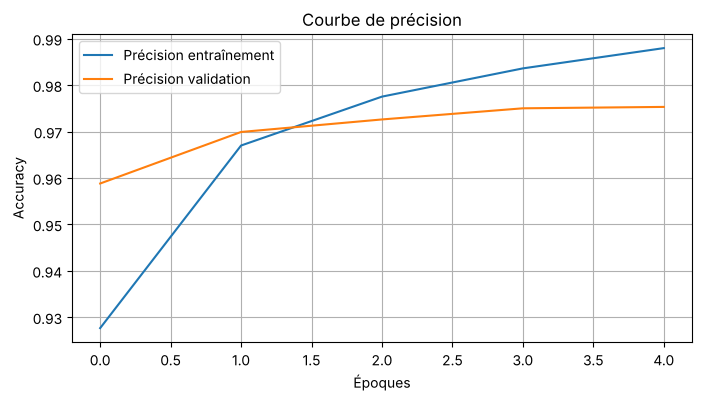

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

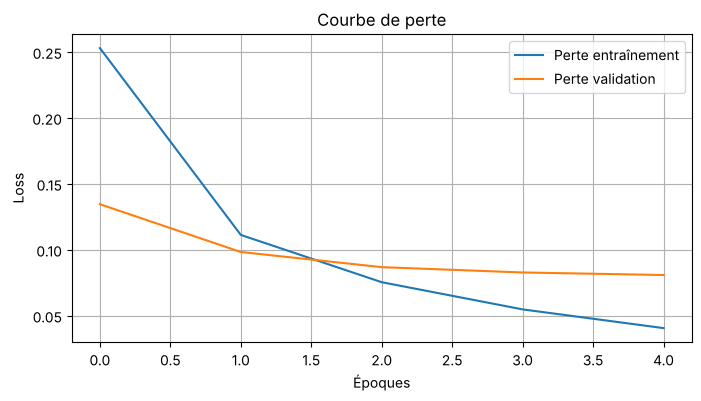

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Réponses
1. **Observation** : les deux courbes montent rapidement puis s'aplatissent. La courbe d'entraînement passe au-dessus de la validation dès la 3ᵉ époque (98,8 % contre 97,5 % à la 5ᵉ) et la perte de validation ne baisse presque plus (0,083 → 0,081) alors que la perte d'entraînement continue de diminuer (0,055 → 0,041) : l'écart commence à se creuser, signe d'un début de surapprentissage. Au-delà de 5 époques, le gain en validation serait marginal.
2. **Détecter visuellement un surapprentissage** : la courbe d'entraînement continue de progresser alors que celle de validation stagne ou se dégrade ; sur les courbes de perte, `val_loss` remonte pendant que `loss` continue de baisser. L'écart se creuse.
3. **Remède** : `EarlyStopping(monitor='val_loss', restore_best_weights=True)`, Dropout, régularisation L2, augmentation de données.
4. **Si les courbes divergent** : arrêter l'entraînement à l'époque où la validation est la meilleure, régulariser, réduire la capacité du modèle, diminuer le taux d'apprentissage ou enrichir les données.

## 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


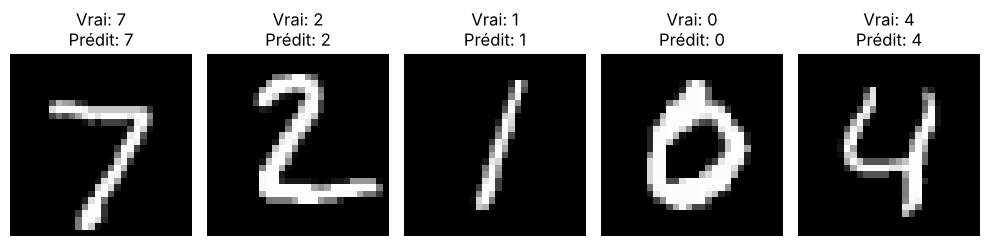

In [10]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Images mal classées: 247 / 10000


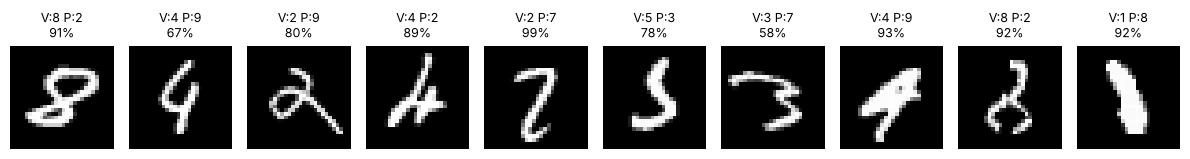

In [11]:
y_pred = np.argmax(predictions, axis=1)
erreurs = np.where(y_pred != y_test)[0]
print(f"Images mal classées: {len(erreurs)} / {len(y_test)}")

plt.figure(figsize=(12, 3))
for k, i in enumerate(erreurs[:10]):
    plt.subplot(1, 10, k + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"V:{y_test[i]} P:{y_pred[i]}\n{predictions[i].max():.0%}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

### Réponses
1. **Erreurs** : oui. Les 5 premières images de test sont toutes bien classées, mais le modèle se trompe sur **247 images sur 10 000 (2,47 %)**. Les erreurs affichées portent surtout sur des chiffres ambigus : des 4 lus comme des 9 (boucle fermée), des 2 lus comme des 7 ou des 9, des 8 lus comme des 2, un 3 très incliné lu comme un 7, un 1 très épais lu comme un 8. Certaines erreurs sont commises avec une forte confiance (jusqu'à 99 %).
2. **Expliquer une prédiction erronée** : chiffres mal écrits ou ambigus (4/9, 3/5, 7/2, 1/7), traits très épais ou très fins, chiffres décentrés ou inclinés. Le réseau dense traite chaque pixel indépendamment et ignore la structure spatiale : un léger décalage du tracé suffit à le tromper.
3. **Améliorer la précision** : un CNN (couches Conv2D + MaxPooling) exploite les motifs locaux et est robuste aux translations ; il atteint couramment plus de 99 % sur MNIST. On peut aussi ajouter Dropout, BatchNormalization et de l'augmentation de données.

## Rapport — synthèse
| Élément | Valeur |
|---|---|
| Architecture | Flatten → Dense(128, ReLU) → Dense(10, Softmax) |
| Paramètres | 101 770 |
| Époques / batch | 5 / 32 |
| Précision finale (test) | 97,53 % |
| Perte finale (test) | 0,0808 |

### Analyse personnelle
Le réseau dense à une couche cachée atteint **97,53 %** de précision sur le jeu de test en seulement 5 époques (environ 30 secondes sur CPU), ce qui confirme qu'un modèle simple suffit à capter l'essentiel de MNIST. Les courbes montrent un apprentissage rapide puis un plateau en validation dès la 3ᵉ époque, alors que la précision d'entraînement continue de monter (98,8 %) : l'écart d'environ 1,3 point marque un début de surapprentissage. Les 247 erreurs restantes concernent des chiffres mal formés ou ambigus (4/9, 2/7, 3/5, 8/2), que le réseau dense, aveugle à la structure spatiale de l'image, ne sait pas distinguer.
La principale difficulté est d'interpréter la stagnation de la validation et de choisir le bon nombre d'époques ; l'usage du jeu de test comme validation, imposé par l'énoncé, biaise aussi légèrement l'évaluation finale.
Pistes d'amélioration : passer à un CNN (Conv2D + MaxPooling, > 99 % attendu), ajouter Dropout ou une régularisation L2, utiliser `EarlyStopping` et un vrai jeu de validation séparé, augmenter la couche cachée (256 neurones) ou en ajouter une seconde, ajuster le taux d'apprentissage d'Adam et la taille de batch, et recourir à l'augmentation de données (petites rotations et translations).